# Experiment 1, follow-up: added value, the over-budget confound, and the live pre-screen

Reads the outputs of `scripts/06_incremental_value.py` (on `main`) and `scripts/07_prescreen_analysis.py` (on `prescreen`).

**How to read the scores.** All predictions are out-of-fold with leave-one-run-out cross-validation. The probe layer is chosen inside each training split, so the scores carry no layer-selection bias.
Models: **M** = metadata (operator, generation, parent fitness / failure / over-budget status, prompt length); **T** = text (code TF-IDF, entropy, log-prob, length); **P** = activation probe. Intervals are 95% bootstrap intervals over LLaMEA runs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

MI_ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(MI_ROOT))
from common.paths import data_dir, results_dir
from common.plotting import INK, NEUTRAL, POSITION_COLORS, POSITION_LABELS, SERIES, setup

setup()
EXP = "exp01_probing"
TAG = "main"
PRESCREEN_TAG = "prescreen"
fu = results_dir(EXP, TAG) / "followup"
inc = pd.read_csv(fu / "incremental.csv")
strata = pd.read_csv(fu / "strata.csv")

## 1. Do the activations add information beyond metadata and text?

In [2]:
scores = inc[~inc["model"].str.contains(" - ")].pivot_table(
    index=["target", "position"], columns="model", values="score"
)[["M", "M+T", "P", "M+P", "M+T+P"]]
scores.round(3)

model                          M    M+T      P    M+P  M+T+P
target        position                                      
child_failed  gen_mean     0.642  0.775  0.850  0.848  0.853
              last         0.642  0.775  0.652  0.643  0.770
              prompt_mean  0.642  0.775  0.610  0.653  0.772
child_fitness gen_mean     0.766  0.797  0.677  0.802  0.810
              last         0.766  0.797  0.485  0.765  0.797
              prompt_mean  0.766  0.797  0.582  0.765  0.800
improved      gen_mean     0.664  0.683  0.613  0.672  0.680
              last         0.664  0.683  0.605  0.653  0.672
              prompt_mean  0.664  0.683  0.570  0.664  0.682
over_budget   gen_mean     0.911  0.926  0.938  0.964  0.956
              last         0.911  0.926  0.696  0.912  0.929
              prompt_mean  0.911  0.926  0.804  0.914  0.924

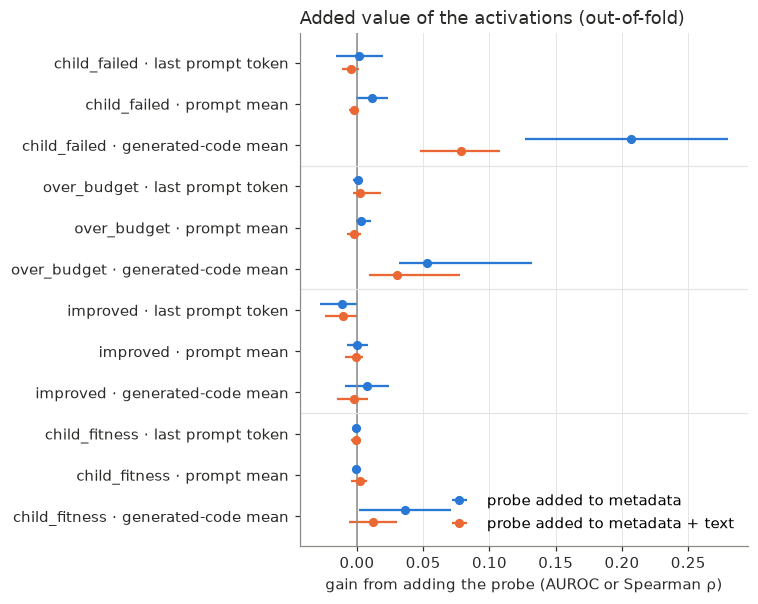

In [3]:
deltas = inc[inc["model"].isin(["M+P - M", "M+T+P - M+T"])].copy()
order = ["child_failed", "over_budget", "improved", "child_fitness"]
positions = ["last", "prompt_mean", "gen_mean"]
rows = [(t, p) for t in order for p in positions]
fig, ax = plt.subplots(figsize=(7, 5.6))
for k, (comp, color, off) in enumerate(
    [("M+P - M", SERIES[0], -0.15), ("M+T+P - M+T", SERIES[1], 0.15)]
):
    d = deltas[deltas["model"] == comp].set_index(["target", "position"])
    for i, key in enumerate(rows):
        r = d.loc[key]
        ax.errorbar(
            r["score"], i + off,
            xerr=[[r["score"] - r["ci_low"]], [r["ci_high"] - r["score"]]],
            fmt="o", color=color, ms=5, lw=1.5, capsize=0,
            label=("probe added to metadata" if comp == "M+P - M" else
                   "probe added to metadata + text") if i == 0 else None,
        )
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{t} · {POSITION_LABELS[p]}" for t, p in rows])
ax.invert_yaxis()
for i in range(3, len(rows), 3):
    ax.axhline(i - 0.5, color="#e4e3df", lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("gain from adding the probe (AUROC or Spearman ρ)")
ax.set_title("Added value of the activations (out-of-fold)", loc="left", color=INK)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(results_dir(EXP, TAG) / "incremental_value.png", dpi=150)

## 2. Over-budget: is the signal inherited from the parent?

Of the working children whose parent overspent, 99% overspend too, so the parent's status alone is a strong predictor (it is part of **M** here).
Within a stratum the parent's status is constant and cannot explain the prediction. With 773 of 780 positives, the "parent over budget" stratum is not testable.

In [4]:
strata.round(3)

,position,stratum,n,positives,M,M+T,P,M+P,M+T+P,P_ci_low,P_ci_high,M+T_ci_low,M+T_ci_high
0,last,parent within budget,154,47,0.438,0.595,0.468,0.435,0.606,0.219,0.600,0.504,0.747
1,last,no working parent,56,43,0.466,0.680,0.405,0.466,0.707,0.316,0.493,0.576,0.807
2,last,parent over budget,780,773,0.133,0.278,0.501,0.141,0.341,0.403,0.755,0.138,0.394
3,prompt_mean,parent within budget,154,47,0.438,0.595,0.472,0.453,0.560,0.304,0.582,0.494,0.754
4,prompt_mean,no working parent,56,43,0.466,0.680,0.480,0.466,0.696,0.388,0.597,0.576,0.809
5,prompt_mean,parent over budget,780,773,0.133,0.278,0.572,0.174,0.262,0.397,0.942,0.139,0.385
6,gen_mean,parent within budget,154,47,0.438,0.595,0.782,0.769,0.744,0.720,0.979,0.491,0.755
7,gen_mean,no working parent,56,43,0.466,0.680,0.878,0.859,0.846,0.774,0.957,0.583,0.810
8,gen_mean,parent over budget,780,773,0.133,0.278,0.829,0.725,0.623,0.749,0.964,0.142,0.391


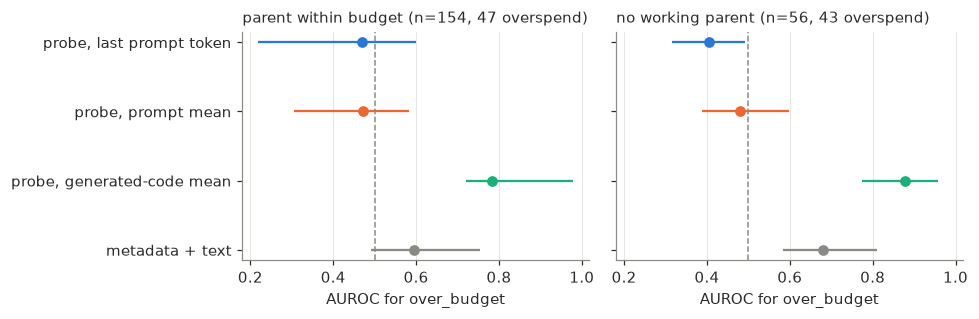

In [5]:
testable = ["parent within budget", "no working parent"]
series = [("P", p, POSITION_COLORS[p], f"probe, {POSITION_LABELS[p]}") for p in positions]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for ax, stratum in zip(axes, testable):
    s = strata[strata["stratum"] == stratum].set_index("position")
    n, pos_n = s.iloc[0]["n"], s.iloc[0]["positives"]
    items = [(f"{lbl}", s.loc[p, "P"], s.loc[p, "P_ci_low"], s.loc[p, "P_ci_high"], c)
             for _, p, c, lbl in series]
    g = s.loc["gen_mean"]
    items.append(("metadata + text", g["M+T"], g["M+T_ci_low"], g["M+T_ci_high"], NEUTRAL))
    for i, (lbl, v, lo, hi, c) in enumerate(items):
        ax.errorbar(v, i, xerr=[[v - lo], [hi - v]], fmt="o", color=c, ms=6, lw=1.5)
    ax.set_yticks(range(len(items)))
    ax.set_yticklabels([it[0] for it in items] if ax is axes[0] else [])
    ax.invert_yaxis()
    ax.axvline(0.5, color=NEUTRAL, lw=1, ls="--")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{stratum} (n={n}, {pos_n} overspend)", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("AUROC for over_budget")
fig.tight_layout()
fig.savefig(results_dir(EXP, TAG) / "over_budget_strata.png", dpi=150)

## 3. Live pre-screen on new seeds (`prescreen`)

Probe and threshold frozen from `main` (`child_failed`, generated-code mean, layer 21, threshold = 80th percentile of the out-of-fold scores on `main`).
Seeds 100-111, each run twice: **shadow** (LLaMEA sees everything) and **screened** (flagged code is shown as failed). Every algorithm is still evaluated, so the true label is known for all.

In [6]:
pres = results_dir(EXP, PRESCREEN_TAG)
pmeta = pd.read_csv(data_dir(EXP, "processed", PRESCREEN_TAG) / "meta.csv", dtype={"record_id": str})
oof_main = pd.read_csv(results_dir(EXP, TAG) / "oof_child_failed_gen_mean.csv")
threshold = pd.read_json(results_dir(EXP, TAG) / "probes" / "probes.json")["child_failed_gen_mean_L21"]["threshold"]
pd.read_csv(pres / "screen_metrics.csv").round(3)

,condition,n,failure_rate,auroc,flagged,failures_caught,working_lost,top_decile_lost,precision
0,all,2400,0.165,0.860,0.235,0.688,0.145,0.098,0.484
1,screened,1200,0.183,0.856,0.212,0.618,0.120,0.067,0.535
2,shadow,1200,0.148,0.878,0.258,0.774,0.169,0.128,0.442
3,all / init,96,0.219,0.782,0.354,0.667,0.267,0.250,0.412
4,all / new,774,0.289,0.855,0.398,0.786,0.240,0.250,0.571
5,all / refine,799,0.141,0.779,0.183,0.504,0.130,0.088,0.390
6,all / simplify,731,0.053,0.930,0.104,0.667,0.072,0.071,0.342


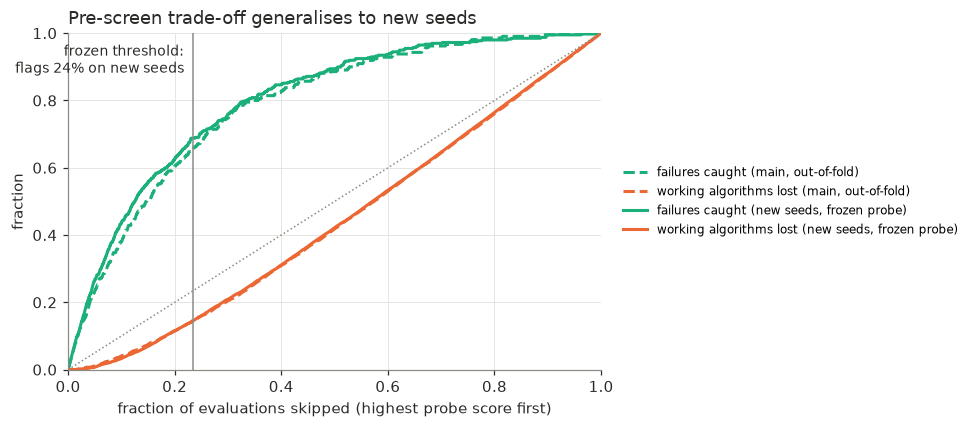

In [7]:
def tradeoff(y, score):
    order = np.argsort(-score)
    y = np.asarray(y)[order]
    k = np.arange(1, len(y) + 1)
    return k / len(y), np.cumsum(y) / y.sum(), np.cumsum(1 - y) / (1 - y).sum()

fig, ax = plt.subplots(figsize=(9, 4))
curves = [
    ("main, out-of-fold", oof_main["child_failed"], oof_main["pred"], "--"),
    ("new seeds, frozen probe", pmeta["child_failed"], pmeta["prescreen_score"], "-"),
]
for lbl, y, s, ls in curves:
    f, caught, lost = tradeoff(y, np.asarray(s))
    ax.plot(f, caught, color=SERIES[2], ls=ls, label=f"failures caught ({lbl})")
    ax.plot(f, lost, color=SERIES[1], ls=ls, label=f"working algorithms lost ({lbl})")
flag_rate = (pmeta["prescreen_score"] > threshold).mean()
ax.axvline(flag_rate, color=NEUTRAL, lw=1)
ax.annotate(f"frozen threshold:\nflags {flag_rate:.0%} on new seeds", (flag_rate, 0.97),
            xytext=(-6, 0), textcoords="offset points", va="top", ha="right", color=INK, fontsize=9)
ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1, ls=":")
ax.set_xlabel("fraction of evaluations skipped (highest probe score first)")
ax.set_ylabel("fraction")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_title("Pre-screen trade-off generalises to new seeds", loc="left", color=INK)
fig.tight_layout()
fig.savefig(pres / "prescreen_heldout.png", dpi=150)

### Effect on the search (paired by seed)

In [8]:
runs = pd.read_csv(pres / "runs.csv")
runs.pivot(index="seed", columns="condition", values=["best", "failure_rate", "flagged"]).round(3)

best        failure_rate         flagged       
condition screened shadow     screened shadow screened shadow
seed                                                         
100          0.566  0.840         0.15   0.15     0.24   0.14
101          0.801  0.559         0.18   0.18     0.22   0.25
102          0.735  0.554         0.15   0.18     0.20   0.25
103          0.783  0.809         0.18   0.15     0.22   0.16
104          0.834  0.582         0.11   0.14     0.17   0.28
105          0.437  0.799         0.18   0.08     0.21   0.18
106          0.770  0.775         0.17   0.09     0.20   0.12
107          0.398  0.438         0.37   0.11     0.46   0.17
108          0.503  0.711         0.15   0.14     0.24   0.25
109          0.382  0.561         0.20   0.09     0.14   0.22
110          0.371  0.539         0.17   0.30     0.16   0.83
111          0.794  0.453         0.19   0.16     0.08   0.25

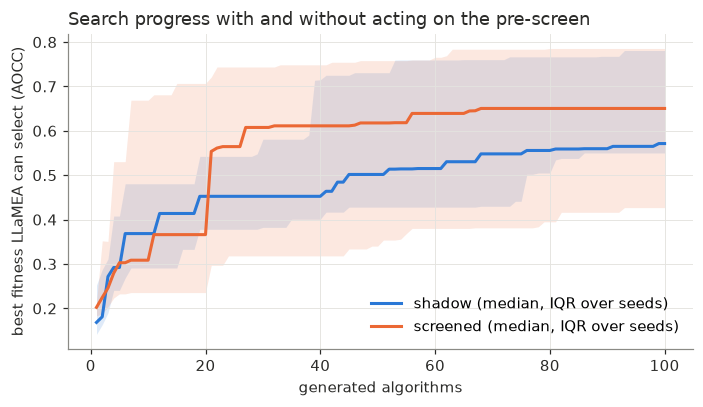

In [9]:
bsf = pd.read_csv(pres / "best_so_far.csv")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for cond, color in [("shadow", SERIES[0]), ("screened", SERIES[1])]:
    d = bsf[bsf["condition"] == cond].pivot_table(index="eval_idx", columns="seed", values="best_so_far")
    d = d.ffill()
    med, lo, hi = d.median(axis=1), d.quantile(0.25, axis=1), d.quantile(0.75, axis=1)
    ax.plot(med.index, med, color=color, label=f"{cond} (median, IQR over seeds)")
    ax.fill_between(med.index, lo, hi, color=color, alpha=0.15, lw=0)
ax.set_xlabel("generated algorithms")
ax.set_ylabel("best fitness LLaMEA can select (AOCC)")
ax.legend(loc="lower right")
ax.set_title("Search progress with and without acting on the pre-screen", loc="left", color=INK)
fig.tight_layout()
fig.savefig(pres / "prescreen_search.png", dpi=150)

## 4. Can a smarter threshold fix the drift? (`scripts/08_threshold_rules.py`)

Four rules were fitted on `main`'s out-of-fold scores, all targeting 20% flagged, and replayed online on the held-out **shadow** runs (whose trajectory never depended on a flag).

In [10]:
rs = pd.read_csv(pres / "rules_summary.csv")
rs[rs["subset"] == "shadow"].drop(columns="subset").round(3)

,rule,n,failure_rate,flagged,failures_caught,working_lost,top_decile_lost,precision,max_phase_deviation
0,fixed,1200,0.148,0.258,0.774,0.169,0.128,0.442,0.161
1,per_operator,1200,0.148,0.244,0.701,0.165,0.138,0.423,0.189
2,risk,1200,0.148,0.263,0.768,0.176,0.147,0.430,0.168
3,running,1200,0.148,0.252,0.746,0.166,0.183,0.437,0.161


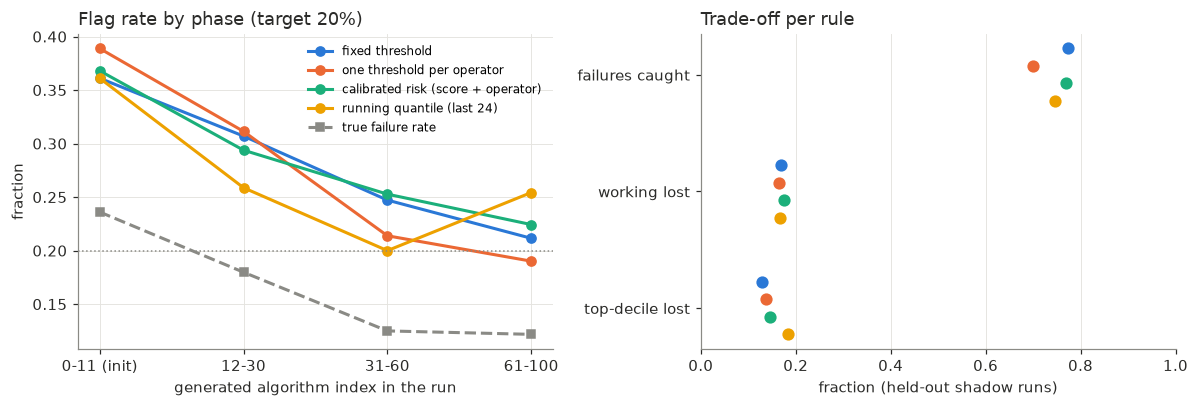

In [11]:
rg = pd.read_csv(pres / "rules_by_group.csv")
rg = rg[(rg["subset"] == "shadow") & (rg["by"] == "phase")]
rule_names = {"fixed": "fixed threshold", "per_operator": "one threshold per operator",
              "risk": "calibrated risk (score + operator)", "running": "running quantile (last 24)"}
phases = list(dict.fromkeys(rg["group"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for k, (rule, label) in enumerate(rule_names.items()):
    d = rg[rg["rule"] == rule].set_index("group").loc[phases]
    ax.plot(range(len(phases)), d["flagged"], "o-", color=SERIES[k], label=label, ms=6)
fail = rg[rg["rule"] == "fixed"].set_index("group").loc[phases]["failure_rate"]
ax.plot(range(len(phases)), fail, "s--", color=NEUTRAL, label="true failure rate", ms=5)
ax.axhline(0.2, color=NEUTRAL, lw=1, ls=":")
ax.set_xticks(range(len(phases))); ax.set_xticklabels(phases)
ax.set_xlabel("generated algorithm index in the run"); ax.set_ylabel("fraction")
ax.set_title("Flag rate by phase (target 20%)", loc="left", color=INK)
ax.legend(fontsize=8)
ax = axes[1]
s = rs[rs["subset"] == "shadow"].set_index("rule").loc[list(rule_names)]
metrics = [("failures_caught", "failures caught"), ("working_lost", "working lost"),
           ("top_decile_lost", "top-decile lost")]
for k, (rule, label) in enumerate(rule_names.items()):
    for j, (m, _) in enumerate(metrics):
        ax.plot(s.loc[rule, m], j + (k - 1.5) * 0.15, "o", color=SERIES[k], ms=7)
ax.set_yticks(range(len(metrics))); ax.set_yticklabels([lbl for _, lbl in metrics])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1); ax.set_xlabel("fraction (held-out shadow runs)")
ax.set_title("Trade-off per rule", loc="left", color=INK)
fig.tight_layout()
fig.savefig(pres / "threshold_rules.png", dpi=150)

## 5. Effect on the search, 36 seeds (`scripts/09_search_effect.py`)

Pre-registered after the first 12 seeds: endpoint = best fitness LLaMEA can select; non-inferiority margin 0.10 AOCC; one-sided paired t-test, alpha 0.05 (lower end of the 90% CI above -0.10).

In [12]:
power = pd.read_csv(pres / "power.csv")
eff = pd.read_csv(pres / "search_effect.csv").T.rename(columns={0: "value"})
display(power.round(3)); eff

,n_seeds,sd_diff,mde_80,ni_power_margin_0.05,ni_power_margin_0.10
0,12,0.229,0.205,0.175,0.410
1,24,0.229,0.140,0.272,0.666
2,36,0.229,0.115,0.359,0.822
3,48,0.229,0.095,0.438,0.909
4,72,0.229,0.080,0.575,0.978


,value
n_seeds,36
shadow_mean,0.627805
screened_mean,0.590983
shadow_median,0.583321
screened_median,0.574679
mean_diff,-0.036822
ci90_low,-0.096418
ci90_high,0.022774
margin,0.1
p_noninferiority,0.040962


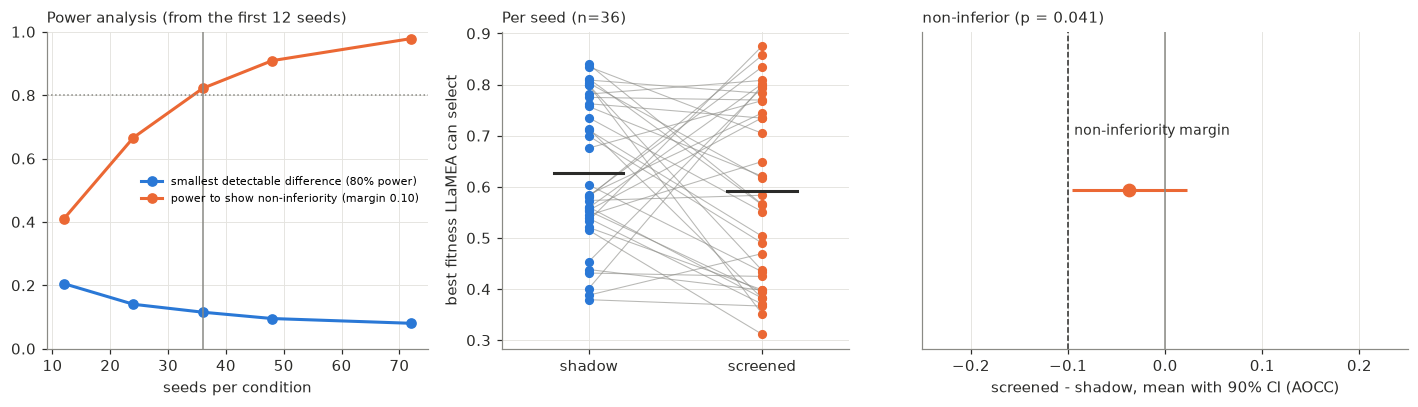

In [13]:
sr = pd.read_csv(pres / "search_runs.csv")
w = sr.pivot(index="seed", columns="condition", values="best").dropna()
e = pd.read_csv(pres / "search_effect.csv").iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.1, 1, 1.4]})
ax = axes[0]
ax.plot(power["n_seeds"], power["mde_80"], "o-", color=SERIES[0], label="smallest detectable difference (80% power)")
ax.plot(power["n_seeds"], power["ni_power_margin_0.10"], "o-", color=SERIES[1], label="power to show non-inferiority (margin 0.10)")
ax.axhline(0.8, color=NEUTRAL, lw=1, ls=":")
ax.axvline(len(w), color=NEUTRAL, lw=1)
ax.set_xlabel("seeds per condition"); ax.set_ylim(0, 1)
ax.set_title("Power analysis (from the first 12 seeds)", loc="left", color=INK, fontsize=10)
ax.legend(fontsize=7, loc="center right")
ax = axes[1]
for seed, r in w.iterrows():
    ax.plot([0, 1], [r["shadow"], r["screened"]], color=NEUTRAL, lw=0.7, alpha=0.6)
for j, (cond, c) in enumerate([("shadow", SERIES[0]), ("screened", SERIES[1])]):
    ax.plot(np.full(len(w), j), w[cond], "o", color=c, ms=5)
    ax.plot([j - 0.2, j + 0.2], [w[cond].mean()] * 2, color=INK, lw=2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["shadow", "screened"]); ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("best fitness LLaMEA can select")
ax.set_title(f"Per seed (n={len(w)})", loc="left", color=INK, fontsize=10)
ax = axes[2]
ax.errorbar(e["mean_diff"], 0, xerr=[[e["mean_diff"] - e["ci90_low"]], [e["ci90_high"] - e["mean_diff"]]],
            fmt="o", color=SERIES[1], ms=8, lw=2, capsize=0)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.axvline(-e["margin"], color=INK, lw=1, ls="--")
ax.annotate("non-inferiority margin", (-e["margin"], 0.35), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK)
ax.set_ylim(-1, 1); ax.set_yticks([])
ax.set_xlim(-0.25, 0.25); ax.grid(axis="y", visible=False)
ax.set_xlabel("screened - shadow, mean with 90% CI (AOCC)")
verdict = "non-inferior" if e["non_inferior"] else "non-inferiority not shown"
ax.set_title(f"{verdict} (p = {e['p_noninferiority']:.3f})", loc="left", color=INK, fontsize=10)
fig.tight_layout()
fig.savefig(pres / "search_effect.png", dpi=150)

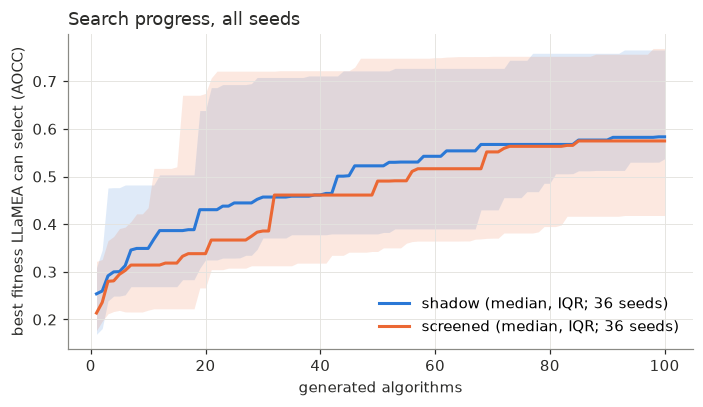

In [14]:
sc = pd.read_csv(pres / "search_curves.csv")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for cond, color in [("shadow", SERIES[0]), ("screened", SERIES[1])]:
    d = sc[sc["condition"] == cond].pivot_table(index="eval_idx", columns="seed", values="best_so_far").ffill()
    med, lo, hi = d.median(axis=1), d.quantile(0.25, axis=1), d.quantile(0.75, axis=1)
    ax.plot(med.index, med, color=color, label=f"{cond} (median, IQR; {d.shape[1]} seeds)")
    ax.fill_between(med.index, lo, hi, color=color, alpha=0.15, lw=0)
ax.set_xlabel("generated algorithms"); ax.set_ylabel("best fitness LLaMEA can select (AOCC)")
ax.legend(loc="lower right")
ax.set_title("Search progress, all seeds", loc="left", color=INK)
fig.tight_layout()
fig.savefig(pres / "prescreen_search_pooled.png", dpi=150)